# Cell source comparison — classical cells vs micro_sam cells

The actin labeler (`label_statement.py`) builds a **boundary band around every cell**, so the quality of the cell outlines decides the quality of the label. This notebook puts two sources of cells side by side:

| Source | How the cells are made |
|---|---|
| **classical** | Gaussian → Otsu footprint → marker watershed (what you have now) |
| **micro_sam** | Foundation-model cell segmentation (Archit et al., *Nature Methods* 2025), produced offline by `generate_microsam_cells.py` |

Everything after the cells (per-cell erosion band, HOG, local-contrast threshold) is **identical** for both, so any difference in the final label comes from the cells.

**Neither source is ground truth.** Agreement between them is evidence, not proof; use your own eyes on the overlays.

Needs: `label_statement.py`, your images in `data/raw`, and the `*_cells.tif` files in `data/cells_microsam`. No TensorFlow, no micro_sam.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace

import label_statement as LS

# ---- EDIT THESE ------------------------------------------------------------
INPUT_DIR = "data/raw"                 # raw images
CELLS_DIR = "data/cells_microsam"      # <stem>_cells.tif written by generate_microsam_cells.py
# ----------------------------------------------------------------------------

P = LS.Params()                        # default labeler settings (expand_px is tuned in section 3)

def cells_file(stem):
    for ext in (".tif", ".tiff", ".png", ".npy"):
        f = os.path.join(CELLS_DIR, f"{stem}_cells{ext}")
        if os.path.exists(f):
            return f
    return None

all_paths = LS.list_images(INPUT_DIR)
image_paths = [p for p in all_paths if cells_file(os.path.splitext(os.path.basename(p))[0])]
missing = [os.path.basename(p) for p in all_paths if p not in image_paths]

print(f"{len(all_paths)} image(s) in '{INPUT_DIR}';  {len(image_paths)} with micro_sam cells in '{CELLS_DIR}'")
if missing:
    print("No cell file for:", missing)
if not image_paths:
    print("\nNothing to compare yet. Run, in an environment that has micro_sam:\n"
          "    python generate_microsam_cells.py --input data/raw --output data/cells_microsam")

6 image(s) in 'data/raw';  6 with micro_sam cells in 'data/cells_microsam'


In [2]:
def dice(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return 2.0 * (a & b).sum() / max(a.sum() + b.sum(), 1)

def iou(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return (a & b).sum() / max((a | b).sum(), 1)

def match_fraction(a, b, thr=0.5):
    """Share of cells in label image `a` that have a cell in `b` overlapping with IoU > thr."""
    na, nb = int(a.max()), int(b.max())
    if na == 0 or nb == 0:
        return 0.0
    inter = np.bincount((a.astype(np.int64) * (nb + 1) + b).ravel(),
                        minlength=(na + 1) * (nb + 1)).reshape(na + 1, nb + 1)
    area_a, area_b = inter.sum(1), inter.sum(0)
    iou_ = inter[1:, 1:] / (area_a[1:, None] + area_b[None, 1:] - inter[1:, 1:] + 1e-9)
    return float((iou_.max(1) > thr).mean())

def touching_percent(cells_raw, expand, shape):
    """After growing every cell by `expand` px: % of cell-edge pixels that touch ANOTHER cell."""
    lab = LS.prepare_external_cells(cells_raw, shape, replace(P, external_cells_expand_px=expand,
                                                              external_cells_min_px=0))
    _, outer, inner = LS.boundary_bands(lab, 3, 8)
    return 100.0 * inner.sum() / max(inner.sum() + outer.sum(), 1)

def agreement_overlay(img, m_classical, m_external):
    rgb = (np.stack([np.clip(img, 0, 1)] * 3, -1) * 255 * 0.55).astype(np.uint8)
    both = m_classical.astype(bool) & m_external.astype(bool)
    only_c = m_classical.astype(bool) & ~m_external.astype(bool)
    only_e = m_external.astype(bool) & ~m_classical.astype(bool)
    rgb[both] = (0, 220, 70)        # green: both sources label it
    rgb[only_c] = (255, 60, 60)     # red:   classical cells only
    rgb[only_e] = (60, 130, 255)    # blue:  micro_sam cells only
    return rgb

## 1. Side by side — every image
Columns: original · classical cells · micro_sam cells · actin label from classical cells · actin label from micro_sam cells · agreement (**green** both, **red** classical only, **blue** micro_sam only).

**What to look for in the cell outlines (columns 2–3):** do the red borders follow the real cell outlines? micro_sam is *not* guaranteed to do well on a dense actin-only stain — if its cells are merged, split through the middle of cells, or cover background, the label made from them will be worse, not better.

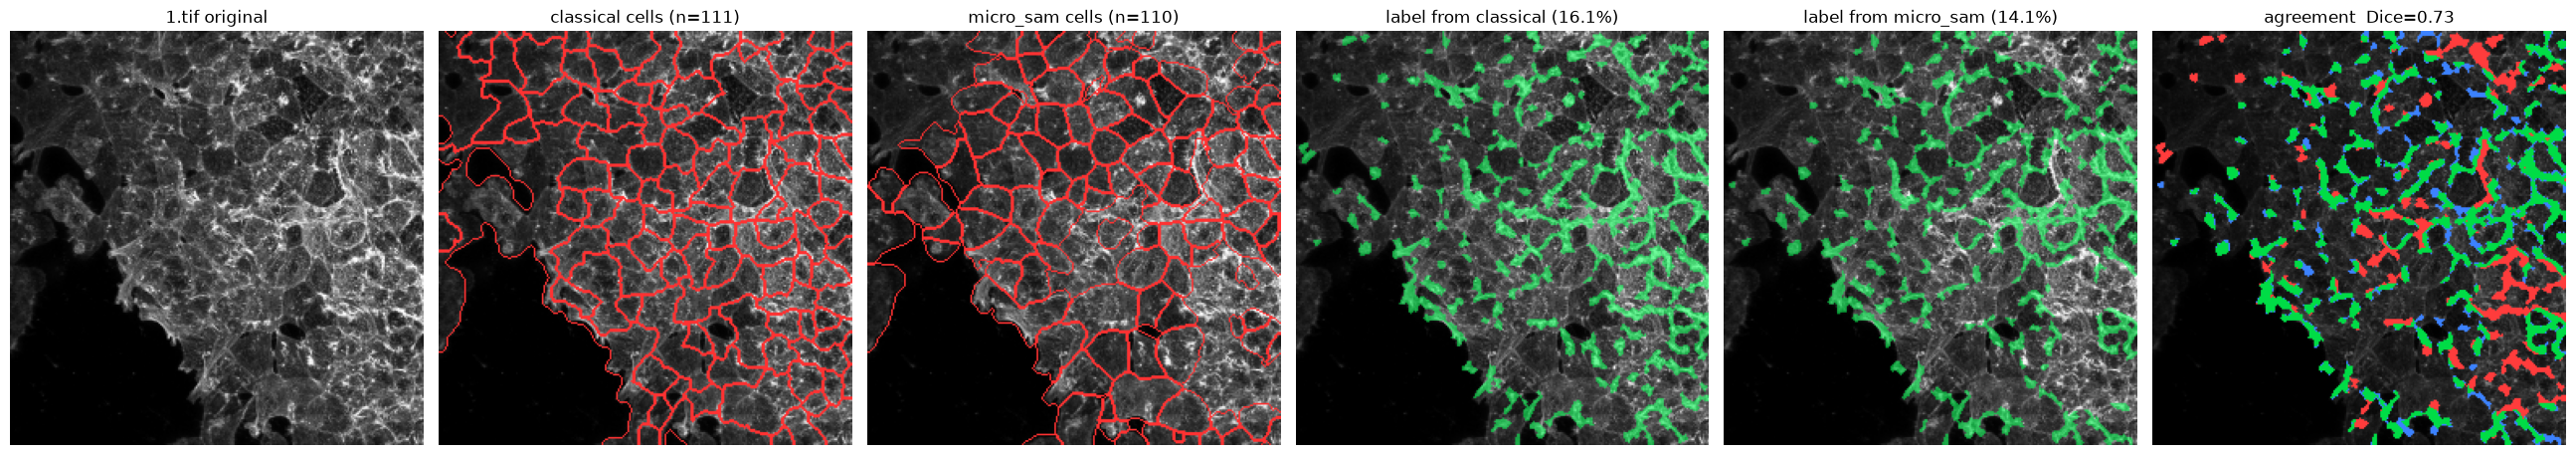

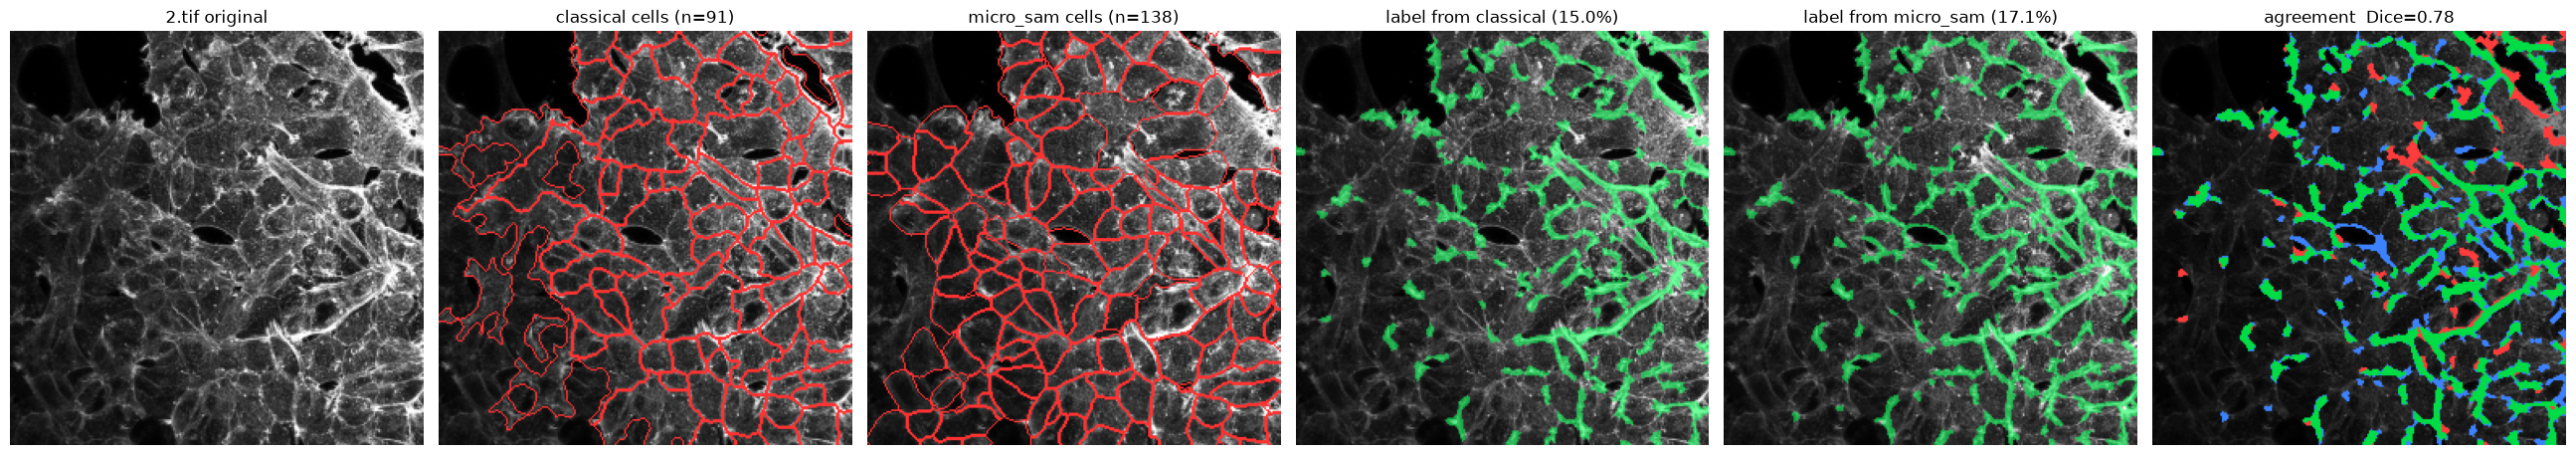

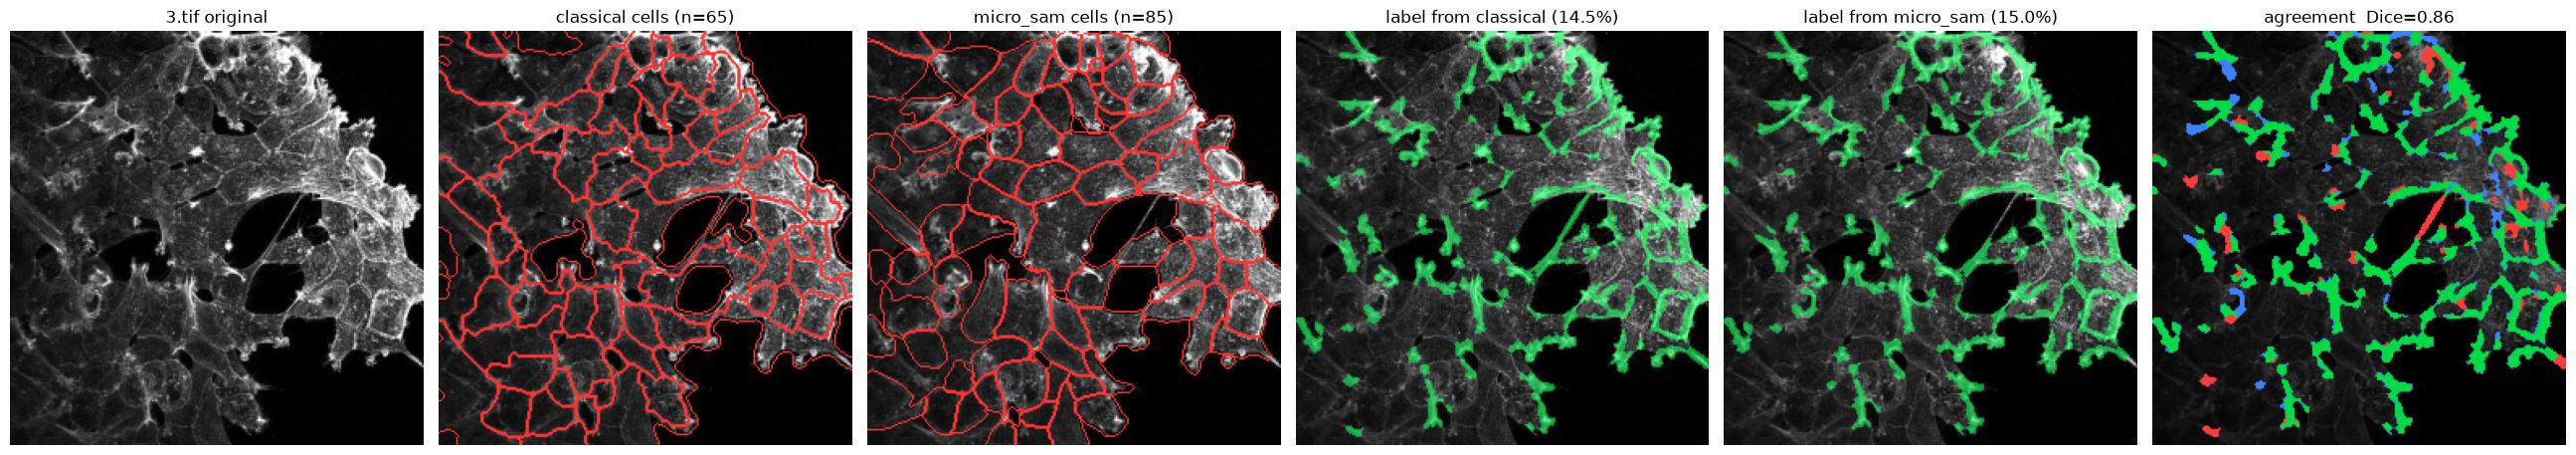

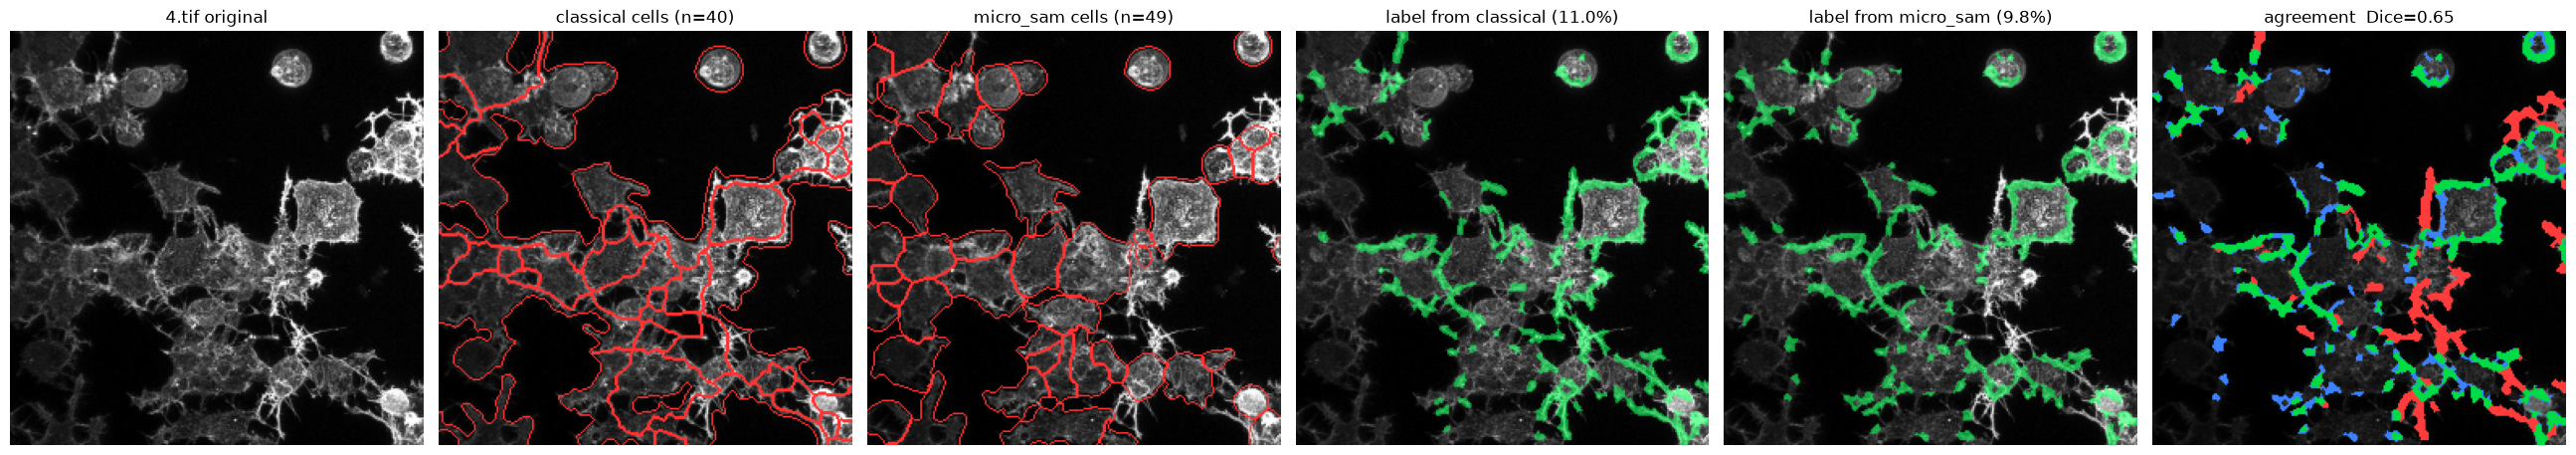

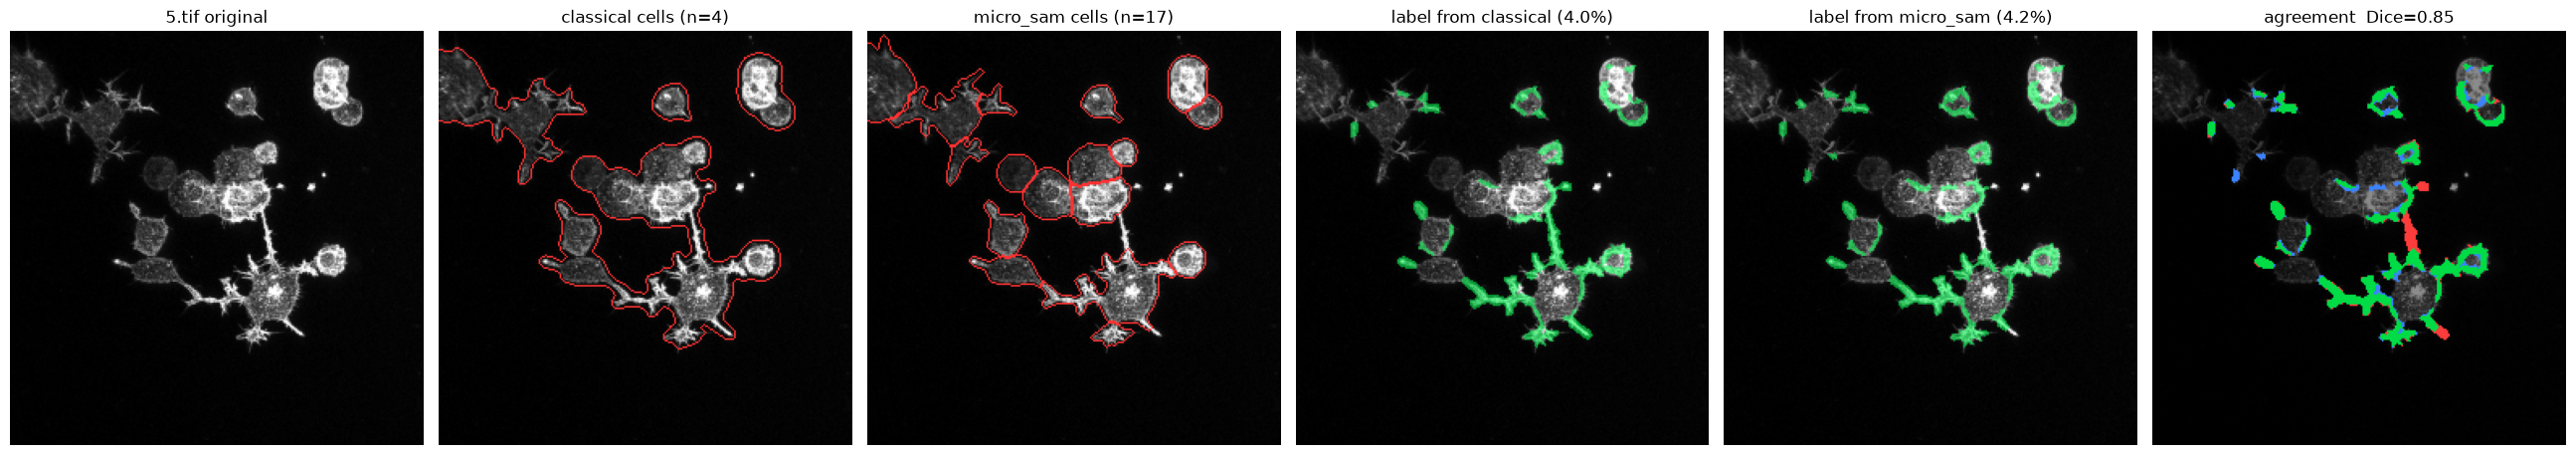

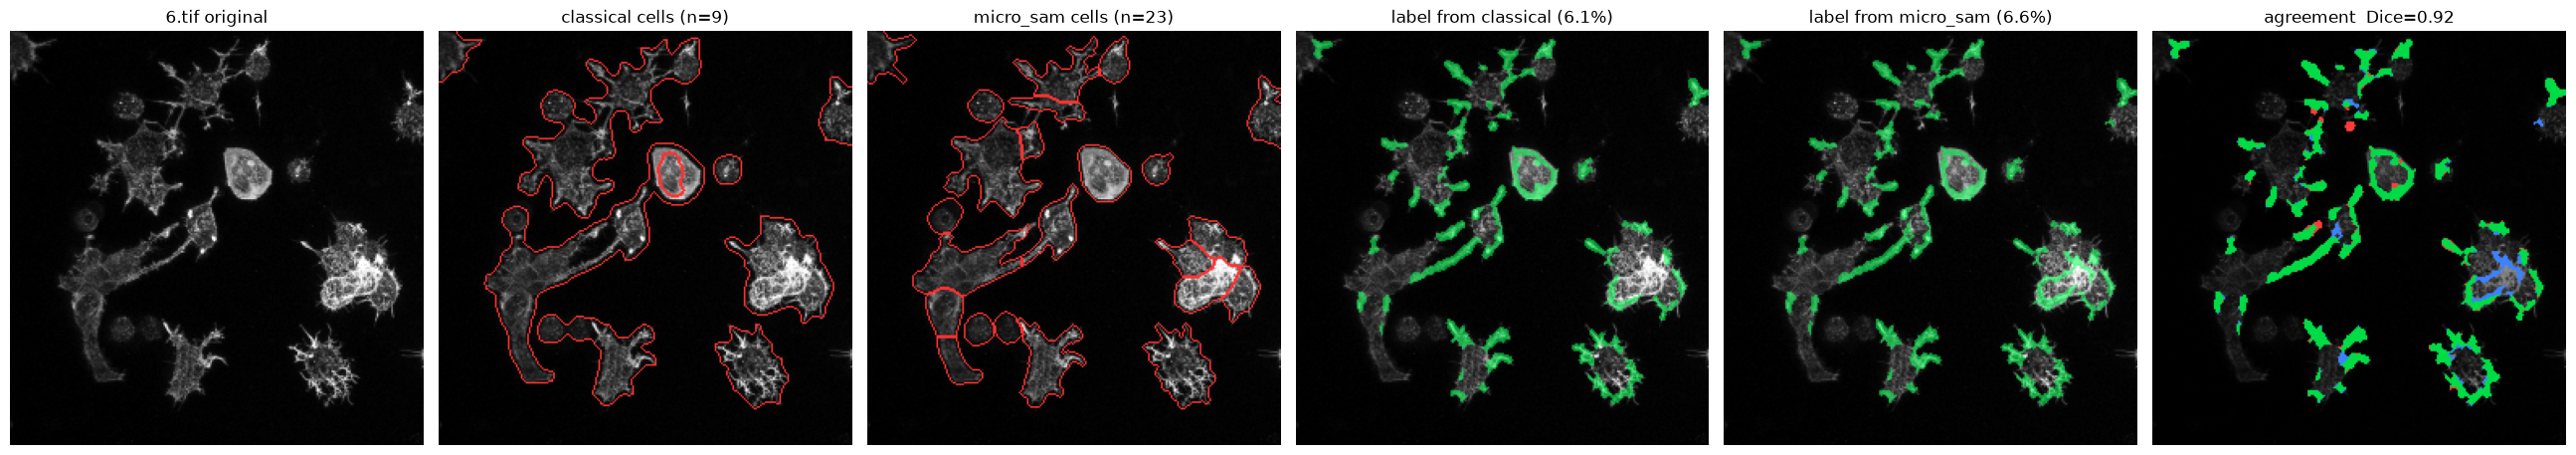

In [3]:
results = {}
for path in image_paths:
    name = os.path.basename(path)
    stem = os.path.splitext(name)[0]
    ext = LS.load_cells_file(cells_file(stem))

    out_c = LS.label_path(path, P)                  # classical cells
    out_e = LS.label_path(path, P, cells=ext)       # micro_sam cells
    results[name] = (out_c, out_e, ext)
    img = out_c["image"]

    fig, axes = plt.subplots(1, 6, figsize=(26, 4.7))
    axes[0].imshow(img, cmap="gray", vmin=0, vmax=1);                      axes[0].set_title(f"{name} original")
    axes[1].imshow(LS.cell_outline_overlay(img, out_c["cells"]));          axes[1].set_title(f"classical cells (n={out_c['n_cells']})")
    axes[2].imshow(LS.cell_outline_overlay(img, out_e["cells"]));          axes[2].set_title(f"micro_sam cells (n={out_e['n_cells']})")
    axes[3].imshow(LS.make_overlay(img, out_c["mask"]));                   axes[3].set_title(f"label from classical ({out_c['actin_percent']:.1f}%)")
    axes[4].imshow(LS.make_overlay(img, out_e["mask"]));                   axes[4].set_title(f"label from micro_sam ({out_e['actin_percent']:.1f}%)")
    axes[5].imshow(agreement_overlay(img, out_c["mask"], out_e["mask"]));  axes[5].set_title(f"agreement  Dice={dice(out_c['mask'], out_e['mask']):.2f}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 2. Numbers

In [4]:
if not results:
    print("No image has a micro_sam cell file yet, so there is nothing to compare. See the message above.")
else:
    rows = []
    for name, (oc, oe, ext) in results.items():
        ac = np.bincount(oc["cells"].ravel())[1:]
        ae = np.bincount(oe["cells"].ravel())[1:] if oe["n_cells"] else np.array([0])
        rows.append({
            "image": name,
            "cells classical": oc["n_cells"],
            "cells micro_sam": oe["n_cells"],
            "median area classical (px)": int(np.median(ac)) if len(ac) else 0,
            "median area micro_sam (px)": int(np.median(ae)),
            "footprint IoU": round(iou(oc["footprint"], oe["footprint"]), 3),
            "micro_sam cells matched in classical": round(match_fraction(oe["cells"], oc["cells"]), 2),
            "label Dice (classical vs micro_sam)": round(dice(oc["mask"], oe["mask"]), 3),
        })
    df = pd.DataFrame(rows)
    print(df.to_string(index=False))
    print()
    print("Reading it:  'matched' = share of micro_sam cells that overlap a classical cell with IoU > 0.5.")
    print("High everywhere  -> the two sources agree, the cell step is not what limits the label.")
    print("Low matched, very different cell counts -> one source is merging or splitting cells; check the outlines above.")

image  cells classical  cells micro_sam  median area classical (px)  median area micro_sam (px)  footprint IoU  micro_sam cells matched in classical  label Dice (classical vs micro_sam)
1.tif              111              110                         369                         333          0.765                                  0.37                                0.727
2.tif               91              138                         398                         335          0.787                                  0.30                                0.777
3.tif               65               85                         519                         503          0.858                                  0.25                                0.861
4.tif               40               49                         437                         481          0.766                                  0.14                                0.654
5.tif                4               17                        2119   

## 3. Choose `external_cells_expand_px`
Segmenters usually leave a thin background gap between neighbouring cells — exactly where the junction actin lies. A band is only built *inside* cells, so an uncovered gap loses that actin. `external_cells_expand_px` grows every cell by a few pixels (never overlapping a neighbour) to close the gap.

For each image the table shows how the share of cell-edge pixels that **touch another cell** changes with the setting. The notebook suggests the **smallest value after which one more pixel of growth adds under 3 points** (the gaps are closed); going further only fattens the outer edges and starts joining separate clusters. The second table shows the label agreement with the classical-cells label for the same settings (useful as a sanity check only — the classical label is not truth).

In [5]:
if not results:
    print("No image has a micro_sam cell file yet, so there is nothing to compare. See the message above.")
else:
    EXPANDS = [0, 1, 2, 3, 4, 5]
    touch_rows, dice_rows = [], []
    for name, (oc, oe, ext) in results.items():
        shape = P.image_size
        touch_rows.append({"image": name, **{f"expand={e}": round(touching_percent(ext, e, shape), 1) for e in EXPANDS}})
        path = os.path.join(INPUT_DIR, name)
        d = {"image": name}
        for e in EXPANDS:
            o = LS.label_path(path, replace(P, external_cells_expand_px=e), cells=ext)
            d[f"expand={e}"] = round(dice(oc["mask"], o["mask"]), 3)
        dice_rows.append(d)

    print("% of cell-edge pixels that touch another cell (look for where it stops rising):")
    print(pd.DataFrame(touch_rows).to_string(index=False))
    print("\nlabel Dice vs the classical-cells label:")
    print(pd.DataFrame(dice_rows).to_string(index=False))

    # suggestion: smallest expand after which ONE MORE pixel of growth adds < 3 points of touching%
    # (touching% keeps creeping up slowly later, as bigger growth starts joining separate clusters,
    #  so 'close to the maximum' would pick too large a value)
    sugg = []
    for r in touch_rows:
        vals = [r[f"expand={e}"] for e in EXPANDS]
        sugg.append(next((e for e in range(len(EXPANDS) - 1) if vals[e + 1] - vals[e] < 3.0), EXPANDS[-1]))
    print("\nSuggested external_cells_expand_px per image:", dict(zip([r['image'] for r in touch_rows], sugg)),
          "-> use the typical (median) value:", int(np.median(sugg)))

% of cell-edge pixels that touch another cell (look for where it stops rising):
image  expand=0  expand=1  expand=2  expand=3  expand=4  expand=5
1.tif      66.8      72.0      76.1      79.1      81.7      84.4
2.tif      71.5      78.7      83.3      86.5      88.9      91.1
3.tif      60.4      64.2      69.0      72.5      76.3      79.9
4.tif      38.1      41.3      44.5      47.8      51.7      57.2
5.tif      13.3      17.4      21.5      24.3      27.6      31.7
6.tif      12.4      14.2      16.5      18.8      22.9      27.5

label Dice vs the classical-cells label:
image  expand=0  expand=1  expand=2  expand=3  expand=4  expand=5
1.tif     0.616     0.677     0.727     0.763     0.777     0.779
2.tif     0.681     0.740     0.777     0.794     0.798     0.791
3.tif     0.827     0.857     0.861     0.839     0.807     0.759
4.tif     0.609     0.637     0.654     0.653     0.636     0.579
5.tif     0.687     0.790     0.853     0.872     0.839     0.737
6.tif     0.777     

To use the chosen value for training, set it once in `config.py`:

```python
CELL_SOURCE = "microsam"
STATEMENT_PARAMS = dict(external_cells_expand_px=2)   # <- your value
```

## 4. How to decide which cell source to use
1. Look at columns 2–3 of the first figure. Whichever source's red borders follow the true cell outlines better is the better one **for this data**.
2. If micro_sam clearly merges or misses cells, try `--model vit_l_lm`, or tune `--center-distance-threshold` / `--boundary-distance-threshold` in `generate_microsam_cells.py`, and re-run.
3. Whatever you pick, say in the report that there is no hand-drawn ground truth, and that the two label sources were compared visually and by overlap.

## 5. References
* Archit, A. *et al.* **Segment Anything for Microscopy.** *Nature Methods* 22(3):579–591 (2025). DOI 10.1038/s41592-024-02580-4
* Kirillov, A. *et al.* **Segment Anything.** ICCV 2023 *(cited from memory — verify before use)*